In [1]:
import numpy as np
import matplotlib.pyplot as plt

from src.grid import Grid
from src.elementary_solutions import SourceSink, Vortex, InfiniteRowOfVortices
from src.superposition import Superposition

In [73]:
nx, ny = 100, 100                             # number of points in each direction
x_start, x_end = -4.0, 4.0            # boundaries in the x-direction
y_start, y_end = -2.0, 2.0           # boundaries in the y-direction

grid = Grid(x_start=x_start, x_end=x_end, y_start=y_start, y_end=y_end, nx=nx, ny=ny)

In [74]:
gamma = -5

a = 1 / 3 

x_vortices = np.arange(-(11//2), 11//2 + 1) * a

vortices = [
    Vortex(x=x, y=0.0, gamma=gamma)
    for x in x_vortices
]


In [75]:
vortice_row = Superposition(elementary_solutions=vortices)

u, v = vortice_row.velocity_field(grid)

psi = vortice_row.stream_function(grid)

Text(0.5, 1.0, 'Finite Row of Vortices Streamlines')

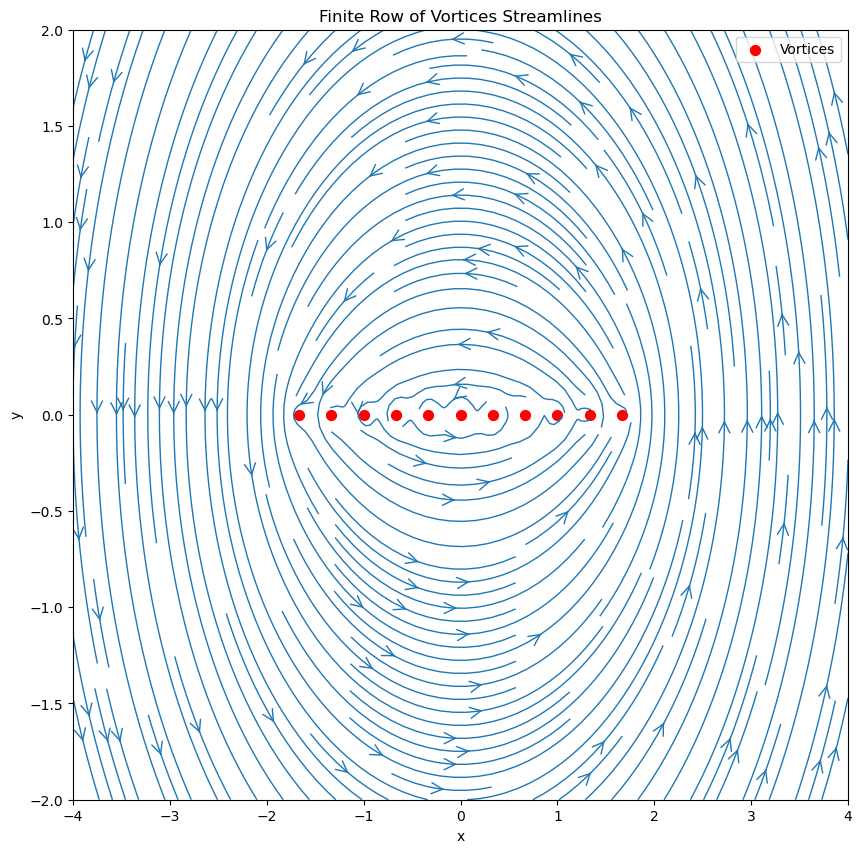

In [76]:
width = 10.0
height = (y_end - y_start) / (x_end - x_start) * width * 2.0

fig, ax = plt.subplots(figsize=(width, height))

ax.streamplot(grid.X, grid.Y, u, v,
                density=2, linewidth=1, arrowsize=2, arrowstyle='->')
ax.scatter([v.x for v in vortices], [v.y for v in vortices], color='r', s=50, marker='o', label='Vortices')
ax.set_xlim(x_start, x_end)
ax.set_ylim(y_start, y_end)
ax.set_xlabel('x')
ax.set_ylabel('y')
ax.legend()
ax.set_title('Finite Row of Vortices Streamlines')

In [77]:
a = 1 / 3

infinite_vortices = InfiniteRowOfVortices(gamma=gamma, spacing=a)

u_inf_vortices, v_inf_vortices = infinite_vortices.velocity_field(grid)

Text(0.5, 1.0, 'Infinite Row of Vortices Streamlines')

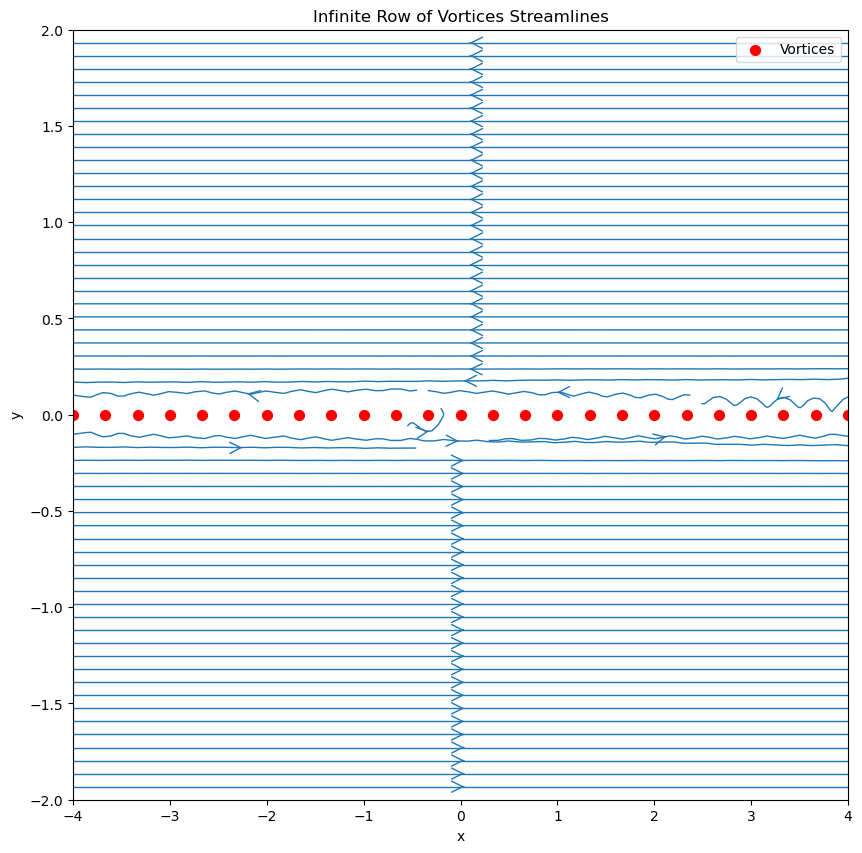

In [78]:
# Integer indices of vortices inside the displayed interval
m = np.arange(
    int(np.ceil(x_start / a)),
    int(np.floor(x_end / a)) + 1
)

x_vortices = m * a


width = 10.0
height = (y_end - y_start) / (x_end - x_start) * width * 2.0

fig, ax = plt.subplots(figsize=(width, height))

ax.streamplot(grid.X, grid.Y, u_inf_vortices, v_inf_vortices,
                density=2, linewidth=1, arrowsize=2, arrowstyle='->')
ax.scatter(x_vortices, np.zeros_like(x_vortices), color='r', s=50, marker='o', label='Vortices')
ax.set_xlim(x_start, x_end)
ax.set_ylim(y_start, y_end)
ax.set_xlabel('x')
ax.set_ylabel('y')
ax.legend()
ax.set_title('Infinite Row of Vortices Streamlines')

## Answers

**Can you notice the differences with the finite case?**

With many vortices extending far beyond the plotting window, the finite row looks the same as the infinite row. With only a few vortices, the differences show up:
- **Ends:** the finite row has two ends, and near them the streamlines wrap around the tips of the row. The infinite row has no ends, so the pattern repeats identically along $x$.
- **Far from the row:** a finite row looks like a single vortex of strength $N\Gamma$, so the velocity decays like $1/r$ and the streamlines become circles. For the infinite row the velocity does not decay: it tends to a constant $u \to \pm\Gamma/(2a)$, and the streamlines are straight lines parallel to the sheet.

**When is the finite case a good approximation of the infinite case?**

When the region you look at is far from the ends of the row and close to the row compared with its length: the row must extend well beyond the plotting window on both sides, and $|y| \ll L$, where $L = (N-1)\,a$ is the length of the row. Then the missing vortices beyond the ends are too far away to matter.

**Think: how is a slip velocity at the vortex sheet consistent with potential flow?**

It is consistent because potential flow has no viscosity, so the no-slip condition does not exist in potential flow. The only condition it enforces at a solid surface is no penetration (zero normal velocity), which the vortex sheet satisfies because the streamlines are parallel to it. The tangential velocity is free, so slip is allowed.

The vortex sheet is exactly a jump in tangential velocity: $u = +\Gamma/(2a)$ on one side and $-\Gamma/(2a)$ on the other. The jump $\Gamma/a = \gamma$ is the strength of the sheet. In a real, viscous flow, this jump is smoothed out into a thin boundary layer.